# Basic Python Data Analysis

## CS 5110 – Big Data Project

This notebook demonstrates fundamental Python data analysis skills, including:

- Data loading and inspection
- Data cleaning and manipulation
- Descriptive statistics
- Data visualization

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print(f"Pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")

Pandas version: 3.1.1
NumPy version: 2.5.4


In [22]:
from pathlib import Path

# Locate the dataset
data_path = Path("../data/raw/dataset.csv")

# Load the dataset
df = pd.read_csv(data_path)

print(f"Rows in dataset: {df.shape[0]:,}")
print(f"Columns in dataset: {df.shape[1]}")

Rows in dataset: 114,000
Columns in dataset: 21


In [23]:
# Display the first five rows
display(df.head())

# Inspect column names, data types, and non-null counts
df.info()

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  str    
 2   artists           113999 non-null  str    
 3   album_name        113999 non-null  str    
 4   track_name        113999 non-null  str    
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          114000 non-nu

## 1. Exploratory Data Inspection

Examining the dataset for missing values, duplicate records, and potential data quality issues before performing analysis.

In [24]:
# 1. Check missing values
print("MISSING VALUES")
print(df.isnull().sum())

# 2. Display rows containing missing values
print("\nROWS WITH MISSING VALUES")
display(df[df.isnull().any(axis=1)])

# 3. Check completely duplicated rows
print("\nDUPLICATE ROWS")
print("Number of duplicate rows:", df.duplicated().sum())

# 4. Check duplicate track IDs
print("\nDUPLICATE TRACK IDs")
print("Number of duplicate track IDs:", df["track_id"].duplicated().sum())

# 5. Check whether Unnamed: 0 is simply a sequential index
print("\nINDEX COLUMN CHECK")
print("Is sequential:", df["Unnamed: 0"].equals(pd.Series(range(len(df)))))

MISSING VALUES
Unnamed: 0          0
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64

ROWS WITH MISSING VALUES


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
65900,65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,0,0,False,0.501,0.583,...,-9.46,0,0.0605,0.69,0.00396,0.0747,0.734,138.391,4,k-pop



DUPLICATE ROWS
Number of duplicate rows: 0

DUPLICATE TRACK IDs
Number of duplicate track IDs: 24259

INDEX COLUMN CHECK
Is sequential: True


## 2. Investigating Duplicate Track IDs

Investigating records with duplicate track IDs to determine whether
they represent legitimate appearances of the same track across
different genres or redundant records.

In [25]:
# Find all rows whose track_id appears more than once
duplicate_tracks = df[
    df.duplicated(subset=["track_id"], keep=False)
].copy()

print("Rows with duplicate track IDs:", len(duplicate_tracks))

# Sort by track_id so matching records appear together
duplicate_tracks = duplicate_tracks.sort_values("track_id")

# Display the first 20 rows
display(duplicate_tracks.head(20))

Rows with duplicate track IDs: 40900


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
15028,15028,001APMDOl3qtx1526T11n1,Pink Sweat$;Kirby,New RnB,Better,0,176320,False,0.613,0.471,...,-6.644,0,0.1070,0.31600,0.000001,0.1170,0.406,143.064,4,chill
103211,103211,001APMDOl3qtx1526T11n1,Pink Sweat$;Kirby,New RnB,Better,0,176320,False,0.613,0.471,...,-6.644,0,0.1070,0.31600,0.000001,0.1170,0.406,143.064,4,soul
85578,85578,001YQlnDSduXd5LgBd66gT,Soda Stereo,Soda Stereo (Remastered),El Tiempo Es Dinero - Remasterizado 2007,38,177266,False,0.554,0.921,...,-4.589,1,0.0758,0.01940,0.088100,0.3290,0.700,183.571,1,punk-rock
100420,100420,001YQlnDSduXd5LgBd66gT,Soda Stereo,Soda Stereo (Remastered),El Tiempo Es Dinero - Remasterizado 2007,38,177266,False,0.554,0.921,...,-4.589,1,0.0758,0.01940,0.088100,0.3290,0.700,183.571,1,ska
2106,2106,003vvx7Niy0yvhvHt4a68B,The Killers,Hot Fuss,Mr. Brightside,86,222973,False,0.352,0.911,...,-5.230,1,0.0747,0.00121,0.000000,0.0995,0.236,148.033,4,alt-rock
3257,3257,003vvx7Niy0yvhvHt4a68B,The Killers,Hot Fuss,Mr. Brightside,86,222973,False,0.352,0.911,...,-5.230,1,0.0747,0.00121,0.000000,0.0995,0.236,148.033,4,alternative
91801,91801,003vvx7Niy0yvhvHt4a68B,The Killers,Hot Fuss,Mr. Brightside,86,222973,False,0.352,0.911,...,-5.230,1,0.0747,0.00121,0.000000,0.0995,0.236,148.033,4,rock
33178,33178,004h8smbIoAkUNDJvVKwkG,Ouse;Powfu,Loners Diary,Lovemark,58,219482,True,0.808,0.331,...,-13.457,1,0.0557,0.13100,0.000000,0.2250,0.337,140.035,4,emo
94239,94239,004h8smbIoAkUNDJvVKwkG,Ouse;Powfu,Loners Diary,Lovemark,58,219482,True,0.808,0.331,...,-13.457,1,0.0557,0.13100,0.000000,0.2250,0.337,140.035,4,sad
35138,35138,006rHBBNLJMpQs8fRC2GDe,Calcinha Preta;Gusttavo Lima,CP 25 Anos (Ao Vivo em Aracaju),Agora Estou Sofrendo - Ao Vivo,47,260510,False,0.605,0.678,...,-3.257,1,0.0311,0.64200,0.000000,0.1570,0.439,125.059,4,forro


 This checks whether the artist, album, track name, popularity, and audio features remain consistent for each duplicated ID.

In [26]:
# Exclude the sequential index and genre from this comparison
comparison_columns = [
    col for col in df.columns
    if col not in ["Unnamed: 0", "track_id", "track_genre"]
]

# Count distinct values in each non-genre column per track ID
variation = (
    duplicate_tracks.groupby("track_id")[comparison_columns]
    .nunique(dropna=False)
)

# Find track IDs where at least one other column varies
inconsistent_tracks = variation.gt(1).any(axis=1)

print("Total duplicated track IDs:", len(variation))
print("IDs with differences beyond genre:", inconsistent_tracks.sum())
print("IDs consistent apart from genre:", (~inconsistent_tracks).sum())

Total duplicated track IDs: 16641
IDs with differences beyond genre: 720
IDs consistent apart from genre: 15921


In [27]:
variation# Identify columns that vary among duplicated track IDs
varying_columns = variation.loc[inconsistent_tracks].gt(1).sum()

print("Columns with differences:")
display(varying_columns[varying_columns > 0].sort_values(ascending=False))

# Get the first 5 inconsistent track IDs
sample_ids = variation.index[inconsistent_tracks][:5]

# Display all records belonging to those IDs
sample_inconsistent = duplicate_tracks[
    duplicate_tracks["track_id"].isin(sample_ids)
].sort_values("track_id")

display(sample_inconsistent)

Columns with differences:


popularity    720
dtype: int64

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
55776,55776,00YwP3wJWiG8IxAA7OS9lo,Anupam Roy,Doorbiney Chokh Rakhbona,Amake Amar Moto Thakte Dao,47,319946,False,0.566,0.419,...,-7.661,1,0.0385,0.77100,0.000000,0.2800,0.186,147.881,4,indian
56324,56324,00YwP3wJWiG8IxAA7OS9lo,Anupam Roy,Doorbiney Chokh Rakhbona,Amake Amar Moto Thakte Dao,47,319946,False,0.566,0.419,...,-7.661,1,0.0385,0.77100,0.000000,0.2800,0.186,147.881,4,indie-pop
57529,57529,00YwP3wJWiG8IxAA7OS9lo,Anupam Roy,Doorbiney Chokh Rakhbona,Amake Amar Moto Thakte Dao,47,319946,False,0.566,0.419,...,-7.661,1,0.0385,0.77100,0.000000,0.2800,0.186,147.881,4,indie
65813,65813,00YwP3wJWiG8IxAA7OS9lo,Anupam Roy,Doorbiney Chokh Rakhbona,Amake Amar Moto Thakte Dao,47,319946,False,0.566,0.419,...,-7.661,1,0.0385,0.77100,0.000000,0.2800,0.186,147.881,4,k-pop
99268,99268,00YwP3wJWiG8IxAA7OS9lo,Anupam Roy,Doorbiney Chokh Rakhbona,Amake Amar Moto Thakte Dao,46,319946,False,0.566,0.419,...,-7.661,1,0.0385,0.77100,0.000000,0.2800,0.186,147.881,4,singer-songwriter
102269,102269,00YwP3wJWiG8IxAA7OS9lo,Anupam Roy,Doorbiney Chokh Rakhbona,Amake Amar Moto Thakte Dao,46,319946,False,0.566,0.419,...,-7.661,1,0.0385,0.77100,0.000000,0.2800,0.186,147.881,4,songwriter
19042,19042,014SIjoLDG1Ku19c5FlDYh,Creedence Clearwater Revival,Pumpkin Patch Hits,I Put A Spell On You,0,271786,False,0.393,0.732,...,-8.188,0,0.0295,0.00471,0.123000,0.0979,0.621,100.410,4,country
91138,91138,014SIjoLDG1Ku19c5FlDYh,Creedence Clearwater Revival,Pumpkin Patch Hits,I Put A Spell On You,3,271786,False,0.393,0.732,...,-8.188,0,0.0295,0.00471,0.123000,0.0979,0.621,100.410,4,rock
68773,68773,02jLfqc9gMo8PkHEGHY3OT,Feid,Si Te La Encuentras Por Ahí,Si Te La Encuentras Por Ahí,83,191573,False,0.743,0.576,...,-3.552,0,0.0760,0.15100,0.000059,0.1280,0.455,171.945,4,latino
88912,88912,02jLfqc9gMo8PkHEGHY3OT,Feid,Si Te La Encuentras Por Ahí,Si Te La Encuentras Por Ahí,82,191573,False,0.743,0.576,...,-3.552,0,0.0760,0.15100,0.000059,0.1280,0.455,171.945,4,reggae


In [28]:
print("Number of inconsistent track IDs per column:\n")
print(
    varying_columns[varying_columns > 0]
    .sort_values(ascending=False)
    .to_string()
)

Number of inconsistent track IDs per column:

popularity    720


We now know:
- All 720 inconsistent track IDs differ only in popularity.
- Their artist, album, track name, duration, and audio features remain identical.
- The other 15,921 duplicated IDs are consistent across every column except genre.
This means there is no evidence that these duplicate IDs represent conflicting audio-feature records.

## 2. Cleaning the dataset


In [29]:
# Remove the redundant sequential index column
df_clean = df.drop(columns=["Unnamed: 0"]).copy()

# Verify cleaning
print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("\nRemaining missing values:")
print(df_clean.isnull().sum())

print("\nNumber of unique track IDs:",
      df_clean["track_id"].nunique())

print("Number of unique genres:",
      df_clean["track_genre"].nunique())

Original dataset shape: (114000, 21)
Cleaned dataset shape: (114000, 20)

Remaining missing values:
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64

Number of unique track IDs: 89741
Number of unique genres: 114


## 4. Descriptive Statistical Analysis

We calculate descriptive statistics for the numerical variables
to understand the dataset's central tendencies, variability,
and overall distributions.

In [30]:
# Select numerical columns
numeric_df = df_clean.select_dtypes(include="number")

# Generate descriptive statistics
display(numeric_df.describe().T)

,count,mean,std,min,25%,50%,75%,max
popularity,114000.0,33.238535,22.305078,0.000,17.00000,35.000000,50.0000,100.000
duration_ms,114000.0,228029.153114,107297.712645,0.000,174066.00000,212906.000000,261506.0000,5237295.000
danceability,114000.0,0.566800,0.173542,0.000,0.45600,0.580000,0.6950,0.985
energy,114000.0,0.641383,0.251529,0.000,0.47200,0.685000,0.8540,1.000
key,114000.0,5.309140,3.559987,0.000,2.00000,5.000000,8.0000,11.000
loudness,114000.0,-8.258960,5.029337,-49.531,-10.01300,-7.004000,-5.0030,4.532
mode,114000.0,0.637553,0.480709,0.000,0.00000,1.000000,1.0000,1.000
speechiness,114000.0,0.084652,0.105732,0.000,0.03590,0.048900,0.0845,0.965
acousticness,114000.0,0.314910,0.332523,0.000,0.01690,0.169000,0.5980,0.996
instrumentalness,114000.0,0.156050,0.309555,0.000,0.00000,0.000042,0.0490,1.000


### 4.1 Investigating Unusual Numerical Values

We examine zero values in duration and tempo, as well as unusually
long tracks, to identify potential anomalies before further analysis.

In [31]:
# Count zero values
print("Zero duration records:", (df_clean["duration_ms"] == 0).sum())
print("Zero tempo records:", (df_clean["tempo"] == 0).sum())

# Investigate unusually long tracks (over 20 minutes)
long_tracks = df_clean[df_clean["duration_ms"] > 20 * 60 * 1000]

print("\nTracks longer than 20 minutes:", len(long_tracks))

# Display the longest 10 tracks
display(
    df_clean.nlargest(10, "duration_ms")[
        ["artists", "track_name", "duration_ms", "track_genre"]
    ]
)

Zero duration records: 1
Zero tempo records: 157



Tracks longer than 20 minutes: 81


,artists,track_name,duration_ms,track_genre
73617,Tale Of Us,Unity (Voyage Mix) Pt. 1,5237295,minimal-techno
10935,Timo Maas,Crossing Wires 002 - Continuous DJ Mix,4789026,breakbeat
10984,Timo Maas,Crossing Wires 002 - Continuous DJ Mix,4789026,breakbeat
24348,Seth Troxler,The Lab 03 - Continuous DJ Mix Part 1,4730302,detroit-techno
73840,Loco Dice,Amnesia Ibiza Underground 10 DJ Mix,4563897,minimal-techno
13344,Mark Farina,House of Om - Mark Farina - Continuous Mix,4447520,chicago-house
13245,Mark Farina,Live In Tokyo - Continuous Mix,4339826,chicago-house
13195,Mark Farina,Greenhouse Construction,4334721,chicago-house
27926,Lenzman;Dan Stezo,"NQ State of Mind, Vol. 1 - Continuous DJ Mix",4246206,drum-and-bass
101390,Ocean Sounds,Ocean Waves Sounds,4120258,sleep


In [32]:
# Inspect the record with zero duration
print("RECORDS WITH ZERO DURATION")
display(
    df_clean[df_clean["duration_ms"] == 0]
)

# Inspect records with zero tempo
print("\nRECORDS WITH ZERO TEMPO")
display(
    df_clean[df_clean["tempo"] == 0].head(20)
)

RECORDS WITH ZERO DURATION


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,0,0,False,0.501,0.583,7,-9.46,0,0.0605,0.69,0.00396,0.0747,0.734,138.391,4,k-pop



RECORDS WITH ZERO TEMPO


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
4131,59gg6zQhSKGVnkT3hWAY3l,Max Richter;Lang Lang,Voyager - Essential Max Richter,The Departure,64,151506,False,0.0,0.03620,0,-22.519,0,0.0,0.994,0.940000,0.0958,0.0,0.0,0,ambient
4379,4acmzQsAeMJa5sGFSog7fu,Dario Marianelli;Jack Liebeck;Benjamin Wallfisch,Jane Eyre - Original Motion Picture Soundtrack,The End of Childhood (feat. Jack Liebeck),55,73266,False,0.0,0.04450,0,-26.440,0,0.0,0.972,0.972000,0.0873,0.0,0.0,0,ambient
4664,1Kb2DqjHRvOcT5xeWtz3t5,Sylvain Chauveau,Des Plumes Dans La Tête,Ferme Les Yeux,53,68493,False,0.0,0.03230,2,-23.636,0,0.0,0.994,0.973000,0.0922,0.0,0.0,0,ambient
45670,6B9Mgf9smWqxDjA35VD6MK,Little Symphony,Rialto Beach,Campomoro,22,148711,False,0.0,0.00108,0,-30.204,1,0.0,0.952,0.991000,0.2420,0.0,0.0,0,guitar
45720,7i5OoyPXtSrqz9jobJfG1F,Little Symphony,Rialto Beach,Ritornello,23,102000,False,0.0,0.00129,7,-29.445,1,0.0,0.969,0.956000,0.1230,0.0,0.0,0,guitar
45729,0pTAEdockvKVSq1hhFqk7O,Little Symphony,Rialto Beach,Amager,22,133624,False,0.0,0.00400,0,-28.326,1,0.0,0.970,0.959000,0.1090,0.0,0.0,0,guitar
45773,1keWmyG6qyBbMagPBdgUKr,Little Symphony,Rialto Beach,Ionian,22,93125,False,0.0,0.02680,7,-30.100,1,0.0,0.964,0.993000,0.1240,0.0,0.0,0,guitar
59221,5BcyxCXrXuw4vsAqAiObWM,Leila Bela,Angra Manyu,Yes! No! I Mean Yes! No I Don't!,0,38333,False,0.0,0.57200,8,-16.286,1,0.0,0.872,0.000175,0.1190,0.0,0.0,0,iranian
59310,6hsyfegVY5yklJneM40mWi,Leila Bela,Angra Manyu,The Exorsism Begins...,0,8586,False,0.0,0.04000,8,-29.714,0,0.0,0.928,0.956000,0.1150,0.0,0.0,0,iranian
59473,48Nt8u7kYSTwE6axtE9hJO,Leila Bela,Angra Manyu,Leaving Her Quantum Journey Behind...,0,50186,False,0.0,0.03140,5,-28.194,0,0.0,0.723,0.000067,0.1290,0.0,0.0,0,iranian


In [33]:
# Analyze all records with zero tempo
zero_tempo = df_clean[df_clean["tempo"] == 0]

print("ZERO-TEMPO FEATURE SUMMARY")
display(
    zero_tempo[
        ["danceability", "energy", "speechiness",
         "acousticness", "instrumentalness", "valence"]
    ].describe().T
)

# Check how many also have zero danceability and valence
print("\nZero tempo AND zero danceability:",
      (zero_tempo["danceability"] == 0).sum())

print("Zero tempo AND zero valence:",
      (zero_tempo["valence"] == 0).sum())

# Which genres contain the most zero-tempo records?
print("\nTOP GENRES WITH ZERO TEMPO")
display(zero_tempo["track_genre"].value_counts().head(15))

# Inspect the zero-duration record separately
print("\nZERO-DURATION RECORD")
display(df_clean[df_clean["duration_ms"] == 0])

ZERO-TEMPO FEATURE SUMMARY


,count,mean,std,min,25%,50%,75%,max
danceability,157.0,0.000000,0.000000,0.0,0.00000,0.000000,0.0000,0.000
energy,157.0,0.122914,0.250220,0.0,0.00002,0.000638,0.0628,0.999
speechiness,157.0,0.000000,0.000000,0.0,0.00000,0.000000,0.0000,0.000
acousticness,157.0,0.496735,0.408839,0.0,0.12200,0.360000,0.9360,0.996
instrumentalness,157.0,0.650488,0.386391,0.0,0.28900,0.864000,0.9840,1.000
valence,157.0,0.000000,0.000000,0.0,0.00000,0.000000,0.0000,0.000



Zero tempo AND zero danceability: 157
Zero tempo AND zero valence: 157

TOP GENRES WITH ZERO TEMPO


track_genre
sleep          138
guitar           4
iranian          4
ambient          3
world-music      3
opera            2
jazz             1
romance          1
show-tunes       1
Name: count, dtype: int64


ZERO-DURATION RECORD


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,0,0,False,0.501,0.583,7,-9.46,0,0.0605,0.69,0.00396,0.0747,0.734,138.391,4,k-pop


In [34]:
df_analysis = df_clean.copy()

# Treat zero tempo and zero duration as unavailable values
df_analysis.loc[df_analysis["tempo"] == 0, "tempo"] = float("nan")
df_analysis.loc[df_analysis["duration_ms"] == 0, "duration_ms"] = float("nan")

print("Missing values after handling unusual numerical values:")
display(df_analysis[["tempo", "duration_ms"]].isnull().sum())

Missing values after handling unusual numerical values:


tempo          157
duration_ms      1
dtype: int64

In [35]:
# Exporting the clean dataset
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "spotify_clean.csv"

df_analysis.to_csv(output_path, index=False)

print("Dataset exported successfully!")
print("File:", output_path)
print("Shape:", df_analysis.shape)

Dataset exported successfully!
File: ../data/processed/spotify_clean.csv
Shape: (114000, 20)


### 4.2 Distribution of Numerical Features

We examine the distributions of numerical audio features to understand
how values are spread across tracks and identify potential patterns
or skewness in the data.


In [36]:
audio_features = [
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo"
]

display(df_analysis[audio_features].describe().T)

,count,mean,std,min,25%,50%,75%,max
danceability,114000.0,0.566800,0.173542,0.000,0.4560,0.580000,0.6950,0.985
energy,114000.0,0.641383,0.251529,0.000,0.4720,0.685000,0.8540,1.000
loudness,114000.0,-8.258960,5.029337,-49.531,-10.0130,-7.004000,-5.0030,4.532
speechiness,114000.0,0.084652,0.105732,0.000,0.0359,0.048900,0.0845,0.965
acousticness,114000.0,0.314910,0.332523,0.000,0.0169,0.169000,0.5980,0.996
instrumentalness,114000.0,0.156050,0.309555,0.000,0.0000,0.000042,0.0490,1.000
liveness,114000.0,0.213553,0.190378,0.000,0.0980,0.132000,0.2730,1.000
valence,114000.0,0.474068,0.259261,0.000,0.2600,0.464000,0.6830,0.995
tempo,113843.0,122.316290,29.653447,30.200,99.4300,122.023000,140.0775,243.372


### 4.3 Visualizing Audio Feature Distributions

Histograms help us examine the frequency distributions of numerical
audio features, identify skewness, and observe how values are spread
across the dataset.

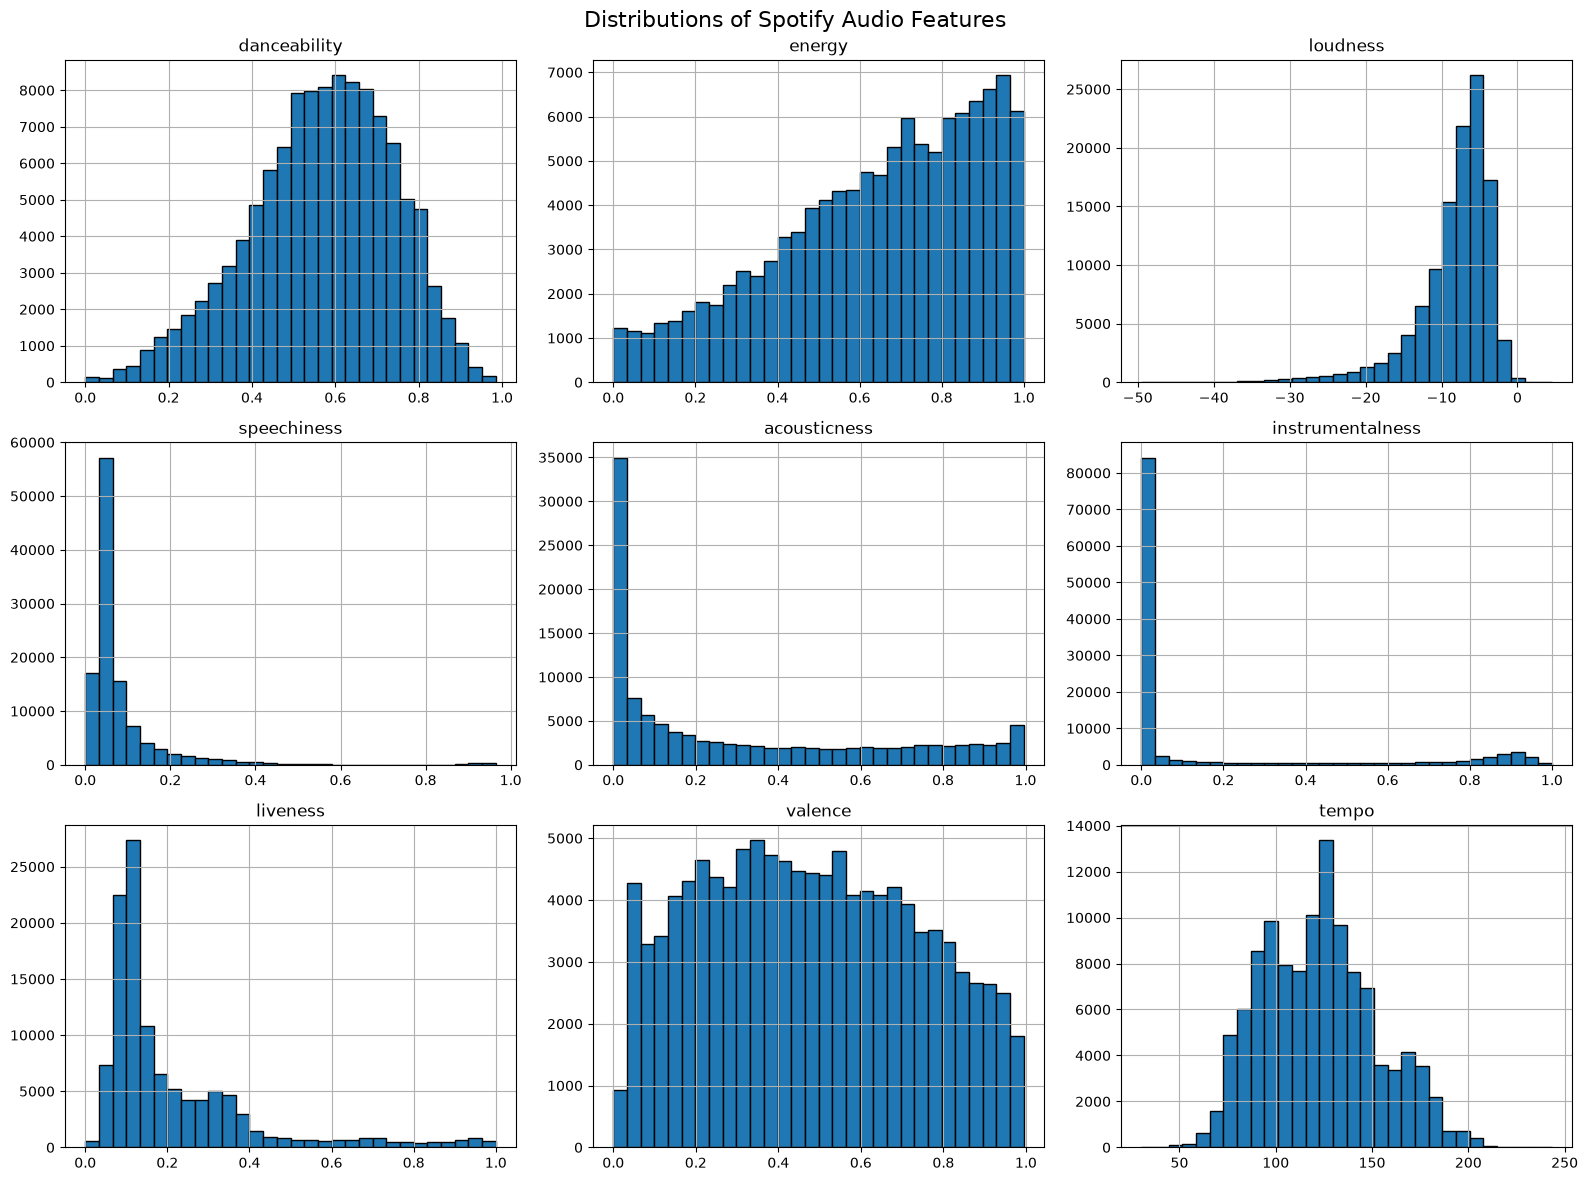

In [37]:
import matplotlib.pyplot as plt

df_analysis[audio_features].hist(
    bins=30,
    figsize=(16, 12),
    edgecolor="black"
)

plt.suptitle("Distributions of Spotify Audio Features", fontsize=16)
plt.tight_layout()
plt.savefig(
    "../figures/audio_feature_distributions.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Key Findings from Audio Feature Distributions

Our distribution analysis revealed several patterns in the Spotify dataset:

**1. Danceability and Energy**
- Danceability is centered around 0.55–0.65, suggesting that most tracks have moderate to relatively high danceability.
- Energy is concentrated toward higher values, indicating that the dataset contains a substantial proportion of energetic tracks.

**2. Loudness**
- Most tracks have loudness values between approximately -5 dB and -10 dB.
- The distribution is relatively concentrated, although some tracks are considerably quieter than the majority.

**3. Speechiness and Instrumentalness**
- Both features have distributions heavily concentrated near zero.
- This suggests that most records are music-oriented rather than spoken-word content or purely instrumental recordings.

**4. Acousticness and Liveness**
- Acousticness has a wide distribution, with concentrations at both lower and higher values, suggesting a mixture of heavily produced and more acoustic recordings.
- Liveness is concentrated at lower values, suggesting that most recordings are more consistent with studio recordings than live performances.

**5. Valence and Tempo**
- Valence is broadly distributed, indicating variety in the perceived musical positivity of tracks.
- Tempo is centered around approximately 122 BPM, with most tracks falling within a moderate tempo range.

**Overall Finding**

The dataset contains a diverse range of musical characteristics, but its distributions lean toward moderately danceable, relatively energetic, predominantly music-oriented tracks, with a substantial concentration of studio-like recordings.

## 5. Correlation Analysis

Correlation analysis helps us identify relationships between numerical
variables. We examine whether changes in one audio feature tend to be
associated with changes in another.

We use Pearson correlation coefficients, which range from -1 to +1:
- +1 indicates a strong positive linear relationship.
- -1 indicates a strong negative linear relationship.
- 0 indicates little or no linear relationship.

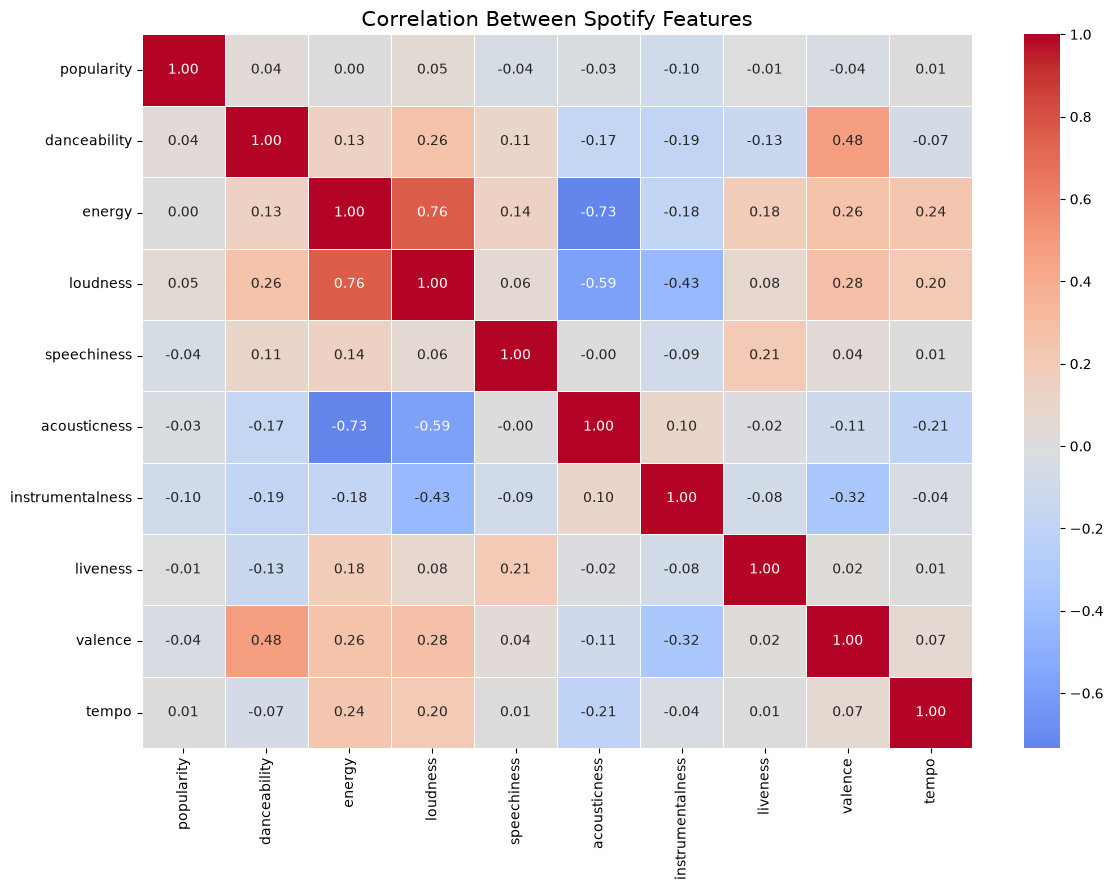

In [38]:

correlation_features = ["popularity"] + audio_features

correlation_matrix = df_analysis[correlation_features].corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0
)

plt.title("Correlation Between Spotify Features", fontsize=15)
plt.tight_layout()
plt.savefig(
    "../figures/correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Key Findings from Correlation Analysis

**1. Energy and Loudness (0.76)**
- A strong positive correlation indicates that higher-energy tracks tend to have higher loudness levels (less negative dB values).

**2. Energy and Acousticness (-0.73)**
- A strong negative correlation suggests that tracks with higher acousticness tend to have lower energy.

**3. Loudness and Acousticness (-0.59)**
- A moderate-to-strong negative correlation indicates that more acoustic tracks tend to have lower loudness levels.

**4. Danceability and Valence (0.48)**
- A moderate positive correlation suggests that more danceable tracks tend to have higher valence scores.

**5. Popularity**
- Popularity has relatively weak linear correlations with individual audio features. This suggests that no single audio feature strongly explains popularity through a linear relationship.

**Overall Finding**

Energy, loudness, and acousticness exhibit the strongest relationships in the dataset. These findings suggest that certain musical characteristics are related, while popularity appears to be influenced by factors beyond any single audio feature.

*Note: Correlation indicates association, not causation.*

## 6. Genre-Level Analysis

We compare average audio characteristics across music genres
to identify differences in popularity, energy, and danceability.

In [39]:
genre_analysis = (
    df_analysis.groupby("track_genre")
    .agg(
        avg_popularity=("popularity", "mean"),
        avg_energy=("energy", "mean"),
        avg_danceability=("danceability", "mean"),
        track_count=("track_id", "count")
    )
)

print("Genres with highest average popularity:")
display(genre_analysis.nlargest(10, "avg_popularity"))

print("Genres with highest average energy:")
display(genre_analysis.nlargest(10, "avg_energy"))

print("Genres with highest average danceability:")
display(genre_analysis.nlargest(10, "avg_danceability"))

Genres with highest average popularity:


,avg_popularity,avg_energy,avg_danceability,track_count
track_genre,,,,
pop-film,59.283,0.604562,0.597146,1000
k-pop,56.896,0.675654,0.647732,1000
chill,53.651,0.426723,0.664346,1000
sad,52.379,0.462470,0.692378,1000
grunge,49.594,0.803290,0.457062,1000
indian,49.539,0.567121,0.592273,1000
anime,48.772,0.674108,0.537451,1000
emo,48.128,0.669967,0.599321,1000
sertanejo,47.866,0.710391,0.591647,1000


Genres with highest average energy:


,avg_popularity,avg_energy,avg_danceability,track_count
track_genre,,,,
death-metal,32.169,0.931470,0.368411,1000
grindcore,14.625,0.924201,0.271854,1000
metalcore,43.477,0.914485,0.423800,1000
happy,21.716,0.910971,0.552847,1000
hardstyle,26.623,0.901246,0.539229,1000
drum-and-bass,26.657,0.876635,0.535486,1000
black-metal,22.449,0.874897,0.296411,1000
heavy-metal,26.226,0.874003,0.428500,1000
party,20.982,0.871237,0.667191,1000


Genres with highest average danceability:


,avg_popularity,avg_energy,avg_danceability,track_count
track_genre,,,,
kids,14.888,0.613129,0.778906,1000
chicago-house,12.339,0.733215,0.766176,1000
reggaeton,23.858,0.738728,0.758521,1000
latino,25.656,0.731797,0.757057,1000
reggae,20.630,0.725791,0.745331,1000
hip-hop,37.759,0.682530,0.736154,1000
dancehall,33.467,0.685262,0.734169,1000
minimal-techno,34.022,0.680272,0.729395,1000
detroit-techno,11.174,0.710512,0.722568,1000


### Key Findings from Genre-Level Analysis

The genre-level comparison revealed several differences in popularity, energy, and danceability:

**1. Popularity**
- Pop-film has the highest average popularity score (59.28), followed by K-pop (56.90) and chill (53.65).
- Genres with high energy do not necessarily have high popularity. For example, death-metal has an average popularity of 32.17.

**2. Energy**
- Death-metal ranks highest in average energy (0.931), followed by grindcore (0.924) and metalcore (0.914).
- These results show that several metal and high-intensity genres have particularly high average energy scores.

**3. Danceability**
- Kids ranks highest in average danceability (0.779), followed by chicago-house (0.766) and reggaeton (0.759).
- Hip-hop also ranks relatively high, with an average danceability score of 0.736.

**Overall Finding**

Different genres exhibit distinct audio characteristics. However, high scores in one metric do not necessarily correspond to high scores in another. For example, kids has the highest average danceability but relatively low popularity. This reinforces the observation that popularity cannot be explained by a single audio feature.

All 114 genres contain 1,000 records in this analysis, providing equal-sized groups for comparison.

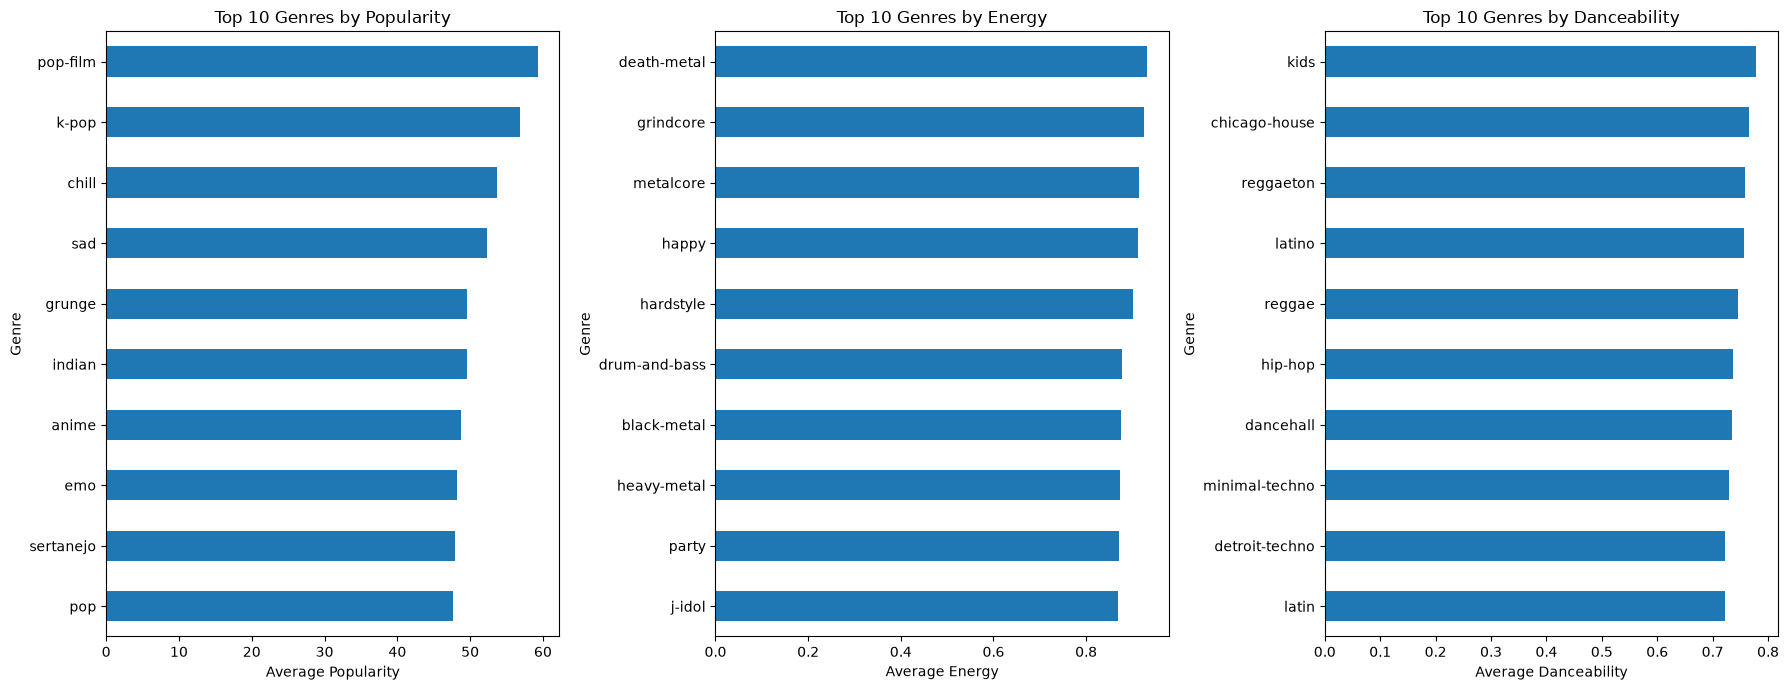

In [40]:
# Select the top 10 genres for each metric
top_popularity = genre_analysis.nlargest(10, "avg_popularity").sort_values("avg_popularity")
top_energy = genre_analysis.nlargest(10, "avg_energy").sort_values("avg_energy")
top_danceability = genre_analysis.nlargest(10, "avg_danceability").sort_values("avg_danceability")

# Create three separate charts
fig, axes = plt.subplots(1, 3, figsize=(18, 7))

top_popularity["avg_popularity"].plot(
    kind="barh", ax=axes[0], title="Top 10 Genres by Popularity"
)
top_energy["avg_energy"].plot(
    kind="barh", ax=axes[1], title="Top 10 Genres by Energy"
)
top_danceability["avg_danceability"].plot(
    kind="barh", ax=axes[2], title="Top 10 Genres by Danceability"
)

axes[0].set_xlabel("Average Popularity")
axes[1].set_xlabel("Average Energy")
axes[2].set_xlabel("Average Danceability")

for ax in axes:
    ax.set_ylabel("Genre")

plt.tight_layout()
plt.savefig(
    "../figures/genre-level_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### 6.1 Top Genres by Popularity, Energy, and Danceability

To visualize the differences between genres, we create three horizontal bar charts showing the top 10 genres for each metric.

**1. Top 10 Genres by Popularity**
- Pop-film leads the chart with the highest average popularity, followed by K-pop, chill, and sad.
- These results indicate that popularity varies across genres and is not necessarily associated with higher energy or danceability.

**2. Top 10 Genres by Energy**
- Death-metal, grindcore, and metalcore lead the chart, with average energy scores above 0.91.
- Several metal and high-intensity genres dominate the highest energy rankings.

**3. Top 10 Genres by Danceability**
- Kids, chicago-house, and reggaeton have the highest average danceability scores, ranging from approximately 0.76 to 0.78.
- Hip-hop, dancehall, and other dance-oriented genres also rank highly.

**Overall Finding**

The charts highlight how different genres have distinct musical characteristics. Popularity, energy, and danceability capture different aspects of music, and a genre that ranks highly in one category may not rank highly in another.

## 7. Overall Findings and Conclusion

### Summary of Findings

Our exploratory analysis of the Spotify dataset, containing 114,000 records across 114 music genres, revealed several important patterns.

**1. Dataset Quality and Cleaning**
- The original dataset contained 21 columns, including a redundant sequential index column, which was removed.
- No completely duplicated records were found.
- Repeated track IDs were retained because the same track can be associated with multiple genres.
- One record contained missing artist, album, and track names. These missing values were retained rather than replaced with invented information.
- Zero tempo and zero duration values were treated as missing for numerical analysis, while preserving all records.

**2. Audio Feature Distributions**
- Danceability is generally centered around moderate values, while energy is concentrated toward higher values.
- Speechiness and instrumentalness are heavily concentrated near zero.
- Acousticness has a wide distribution, reflecting variation in the acoustic characteristics of tracks.
- Tempo is centered around approximately 122 BPM.

**3. Correlation Analysis**
- Energy and loudness have a strong positive correlation (0.76).
- Energy and acousticness have a strong negative correlation (-0.73).
- Danceability and valence have a moderate positive correlation (0.48).
- Popularity has relatively weak linear correlations with individual audio features.

**4. Genre-Level Analysis**
- Pop-film has the highest average popularity score (59.28).
- Death-metal has the highest average energy score (0.931).
- Kids has the highest average danceability score (0.779).
- The results demonstrate that different genres exhibit distinct audio characteristics and that high performance in one metric does not necessarily translate to high performance in another.

### Conclusion

The exploratory analysis provides an overview of the Spotify dataset's structure, quality, and musical characteristics. We identified relationships between audio features, differences in their distributions, and notable variations across music genres.

One important observation is that audio features such as energy, loudness, acousticness, and danceability exhibit meaningful relationships, whereas popularity does not show a strong linear relationship with any individual audio feature.

These findings provide a foundation for the next stages of the project, where more advanced techniques, including clustering and spectral graph partitioning, can be applied to investigate patterns and relationships within the dataset.

*Note: These findings are based on exploratory and descriptive analysis. Correlations represent associations rather than causal relationships.*